# 03 — Phân tích khám phá (EDA): ô nhiễm nặng ở đâu, vào lúc nào, do chất nào

Notebook này gom toàn bộ phần EDA của nhóm vào một chỗ: setup một lần, rồi **Phần A (Ở ĐÂU)**, **Phần B (KHI NÀO)**, **Phần C (CHẤT NÀO)**, kiểm tra độ nhạy và tổng hợp cuối.
Dữ liệu đầu vào là `data/processed/air_quality_8cities.csv` do `01_cleaning` tạo ra, nên chạy `01_cleaning` trước. Hàm dùng chung ở `src/eda_utils.py`.

**Cách chạy:** *Kernel -> Restart & Run All*, từ thư mục `notebooks/`. Hình lưu vào `reports/figures/` với tên `eda_00_*` đến `eda_05_*`.


## Câu hỏi nghiên cứu (mục 1 của báo cáo)

> **Ô nhiễm không khí nặng (AQI từ 201 trở lên) tập trung ở thành phố nào và vào mùa nào trong 8 thành phố Ấn Độ giai đoạn 2015–2020, để cơ quan môi trường và người dân biết nên ưu tiên cảnh báo sức khỏe và giảm phát thải ở đâu, lúc nào?**

Ba câu hỏi phụ (phần chẩn đoán, chỉ nói "có liên quan", **không** nói "gây ra"):
1. Trong **cùng một thành phố**, ô nhiễm có giảm qua các năm không (so cùng các tháng 1–6)?
2. Khi AQI nặng, chất nào ở mức cao nhất?
3. Năm 2020 AQI thấp hơn 2019 cùng kỳ: mùa, xu hướng, lockdown, yếu tố nào có thể liên quan? (không kết luận nguyên nhân)

## Quy ước chung (cả nhóm dùng giống nhau, nếu không biểu đồ sẽ lệch nhau)

| Quy ước | Giá trị |
|---|---|
| Dữ liệu | `data/processed/air_quality_8cities.csv` (đã làm sạch, đã gộp) |
| So sánh giữa các thành phố | chỉ dùng **khoảng chung** (biến `win`), vì chuỗi mỗi thành phố dài ngắn khác nhau |
| "Nặng" | AQI **>= 201** (từ mức *Poor* trở lên theo thang CPCB). Tỉ lệ tính trên số ngày **có AQI** |
| Mùa | Đông (12-2), Hè (3-5), Mưa (6-9), Sau mưa (10-11) |
| Cột dùng làm biến | chỉ cột thiếu < 60% trong thành phố đó; PM10 và NH3 chỉ dùng có điều kiện (xem `Data_dictionary.md`) |
| Từ ngữ | "có liên quan", "đi cùng với". **Không** dùng "gây ra", "làm giảm" |


## Chuẩn biểu đồ (W7), tick đủ trước khi push

- [ ] Tiêu đề là **kết luận có con số** (không phải "AQI theo thành phố")
- [ ] Trục có **nhãn và đơn vị**
- [ ] Biểu đồ cột **bắt đầu từ 0**, sắp theo giá trị (không theo bảng chữ cái)
- [ ] **Một** màu nhấn cho điều muốn người đọc thấy, còn lại màu trung tính
- [ ] Ghi nhãn trực tiếp, bỏ legend nếu chỉ có một nhóm
- [ ] Không dùng biểu đồ tròn, 3D, trục kép; không dùng chỉ đỏ-xanh lá để phân biệt
- [ ] Thử chuyển sang thang xám vẫn đọc được
- [ ] Chú thích có cỡ mẫu và ngày dữ liệu (hàm `finish_chart` đã làm sẵn)


## 0. Setup

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eda_utils import (CITIES, USABLE, SEASON_ORDER, ACCENT, NEUTRAL,
                       vn, load, poor_share, four_families, finish_chart, save_fig, set_style)

set_style()
eda, win, START, END = load()      # eda: toàn bộ 2015-2020 | win: khoảng chung của 8 thành phố (dùng khi so sánh giữa thành phố)

Toàn bộ: 14.056 dòng, 01/01/2015 - 01/07/2020
Khoảng chung (biến win): 14/06/2017 - 01/07/2020, 8.912 dòng; 8.734 ngày có AQI


### Biểu đồ mẫu (đã đủ chuẩn W7, để tham chiếu cách gọi hàm)

Cũng dùng được trong báo cáo như bằng chứng về cỡ mẫu. Các phần A, B, C bên dưới làm cùng khuôn: cột ngang sắp theo giá trị, bắt đầu từ 0, một cột nhấn, nhãn trực tiếp, không legend.

Đã lưu reports/figures/eda_00_sample_size.png


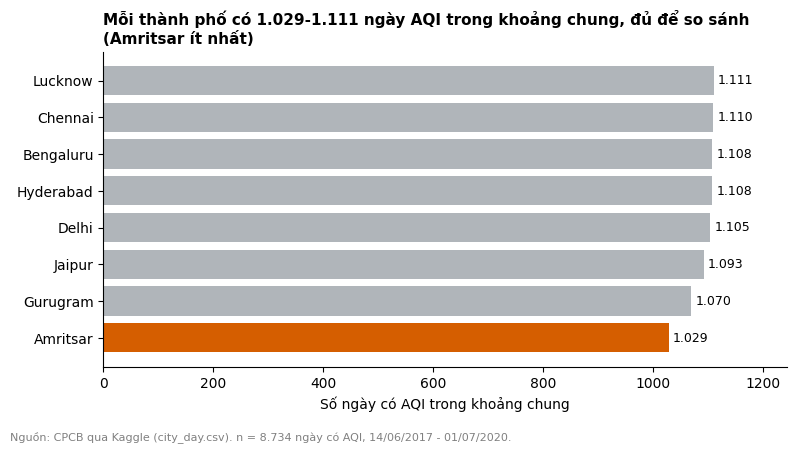

In [2]:
n_days = win.dropna(subset=["AQI"]).groupby("City", observed=True).size().sort_values()   # tăng dần để cột lớn nằm trên cùng

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(n_days.index.astype(str), n_days.values,
               color=[ACCENT if c == n_days.idxmin() else NEUTRAL for c in n_days.index])
ax.bar_label(bars, labels=[vn(v) for v in n_days.values], padding=3, fontsize=9)
ax.set_xlim(0, n_days.max() * 1.12)
ax.set_xlabel("Số ngày có AQI trong khoảng chung"); ax.set_ylabel("")
finish_chart(fig, ax, f"Mỗi thành phố có {vn(n_days.min())}-{vn(n_days.max())} ngày AQI trong khoảng chung, "
                      f"đủ để so sánh ({n_days.idxmin()} ít nhất)", win)
save_fig(fig, "00_sample_size")
plt.show()

## Kiểm tra độ nhạy (cho câu vấn đáp "nếu xoá ngẫu nhiên 10% số dòng, kết luận có đổi không?")

Bỏ ngẫu nhiên 10% số ngày, lặp 200 lần, xem **thứ hạng** các thành phố theo tỉ lệ ngày nặng có đổi không.
Kết quả: các cặp có tỉ lệ gần nhau (Lucknow và Gurugram; Amritsar và Jaipur; Bengaluru và Hyderabad) hay đổi chỗ, nên trong báo cáo **chia theo nhóm** thay vì xếp hạng từng thành phố.

In [3]:
def share(d):                                      # không làm tròn, để thứ hạng không bị hòa giả do làm tròn
    return d.dropna(subset=["AQI"]).groupby("City", observed=True).poor.mean() * 100

rng = np.random.default_rng(42)
base = share(win)
runs = pd.DataFrame([share(win.sample(frac=0.9, random_state=int(rng.integers(1e9)))) for _ in range(200)])
stable = (runs.rank(axis=1, ascending=False) == base.rank(ascending=False)).mean() * 100
sens = pd.DataFrame({"pct_poor_goc": base.round(1), "nho_nhat": runs.min().round(1), "lon_nhat": runs.max().round(1),
                     "thu_hang_giu_nguyen_%": stable.round(0)}).sort_values("pct_poor_goc", ascending=False)
sens

,pct_poor_goc,nho_nhat,lon_nhat,thu_hang_giu_nguyen_%
City,,,,
Delhi,51.0,49.3,53.1,100.0
Lucknow,46.4,45.0,47.7,59.0
Gurugram,46.3,44.6,48.2,59.0
Amritsar,11.4,10.5,12.2,76.0
Jaipur,11.1,10.0,11.8,76.0
Chennai,3.1,2.6,3.4,100.0
Bengaluru,0.2,0.0,0.2,93.0
Hyderabad,0.1,0.0,0.1,93.0


## Câu hỏi vấn đáp đã công bố trước (W8), mỗi người đều phải trả lời được

1. Vì sao xử lý missing theo cách đó? (xem `reports/cleaning_log_8cities.md` và `02_cleaning_evidence.ipynb`)
2. Cơ chế thiếu của cột này là gì, bằng chứng nào? (dòng về cột thiếu >= 20% trong nhật ký)
3. Nếu xoá ngẫu nhiên 10% dòng, kết luận có đổi không? (bảng kiểm tra độ nhạy ở trên)
4. Biểu đồ này có thể đánh lừa người đọc vội ở chỗ nào?
5. **Confounder hợp lý cho quan hệ vừa mô tả là gì?** (câu quyết định điểm diễn giải)

Câu hỏi riêng của đề tài nên chuẩn bị thêm: vì sao dùng khoảng chung? vì sao ngưỡng 201? vì sao tháng 1-6 khi so các năm? vì sao PM10/NH3 không dùng làm biến?


## Ghép báo cáo

1. Mục 4: lấy 5 hình `eda_01`, `eda_02`, `eda_03`, `eda_04`, `eda_05` trong `reports/figures/` (và `eda_00` nếu cần chứng minh cỡ mẫu).
2. Mục 5: gom 3 bảng "phát hiện của phần ..." ở cuối Phần A, B, C (đã tổng hợp ở cuối notebook này), mỗi ý gắn một biểu đồ.
3. Mục 6: lấy từ phần tổng hợp cuối notebook này.
4. Chạy lại **01 -> 02 -> 03** bằng Restart & Run All trước khi nộp.


---
# Phần A — Ở ĐÂU: thành phố nào có nhiều ngày ô nhiễm nặng nhất

### Lưu ý khi đọc phần A
- Các thành phố có tỉ lệ gần nhau **đổi thứ hạng khi bỏ ngẫu nhiên 10% dòng** (xem bảng kiểm tra độ nhạy ở trên): Lucknow và Gurugram, Amritsar và Jaipur, Bengaluru và Hyderabad. Vì vậy hãy **nhóm các thành phố** (ví dụ nhóm rất nặng, nhóm trung bình, nhóm gần như không) thay vì xếp hạng từng thành phố.
- Bảng `skew` > 0 nghĩa là phân phối lệch phải (nhiều ngày thấp, ít ngày rất cao); giải thích điều này bằng lời vì nó quyết định nên dùng **trung vị** hay trung bình.

**Câu vấn đáp phải trả lời được**: confounder nào có thể giải thích khác biệt giữa các thành phố? (gợi ý: số và vị trí trạm đo, quy mô đô thị, địa lý, thời tiết; dữ liệu này **không** có thời tiết và không có vị trí trạm.) Biểu đồ này có thể đánh lừa người đọc vội ở chỗ nào?


## A1. Bảng 4 họ thống kê (AQI, khoảng chung)

In [4]:
stats_city = four_families(win, "AQI", "City").sort_values("median", ascending=False)
stats_city

,n,mean,median,std,iqr,skew,spearman_PM2.5
City,,,,,,,
Delhi,1105,225.38,205.0,121.09,192.00,0.66,0.96
Lucknow,1111,206.98,188.0,112.69,211.00,0.43,0.96
Gurugram,1070,211.55,187.5,112.45,182.00,0.79,0.94
Jaipur,1093,133.52,122.0,54.09,63.00,1.33,0.88
Amritsar,1029,122.45,104.0,76.84,64.00,2.94,0.81
Hyderabad,1108,92.56,89.0,35.22,56.25,0.38,0.93
Chennai,1110,98.94,87.0,39.71,37.00,2.19,0.69
Bengaluru,1108,86.58,81.0,27.57,37.00,1.65,0.80


### Đọc bảng A1 bằng lời

Bảng tính trên **AQI hằng ngày trong khoảng chung** (14/06/2017 – 01/07/2020, 1.114 ngày), sắp theo trung vị giảm dần.

| Cột | Họ thống kê | Nghĩa là gì | Đọc từ bảng này |
|---|---|---|---|
| `n` | cỡ mẫu | Số ngày có AQI | Từ 1.029 (Amritsar) đến 1.111 (Lucknow) trên 1.114 ngày. Amritsar thiếu 85 ngày (7,6%), Gurugram thiếu 44 ngày (khoảng 4%), nên hai thành phố này kém chắc hơn. |
| `mean` | vị trí | Trung bình cộng | Delhi 225, Gurugram 212, Lucknow 207 cao nhất; Bengaluru 87 thấp nhất. Bị kéo lên bởi vài ngày rất cao. |
| `median` | vị trí | Giá trị ở giữa: một nửa số ngày thấp hơn nó | Delhi 205, Lucknow 188, Gurugram 188 (187,5), Jaipur 122, Amritsar 104, Hyderabad 89, Chennai 87, Bengaluru 81. Ít bị ảnh hưởng bởi ngày cực đoan. |
| `std` | phân tán | Độ lệch chuẩn, độ tản quanh trung bình | Lớn nhất ở Delhi (121), nhỏ nhất ở Bengaluru (28). Nhạy với ngày cực đoan. |
| `iqr` | phân tán | Q3 trừ Q1: bề rộng của 50% số ngày ở giữa | Lucknow 211 là lớn nhất, kế đó Delhi 192 và Gurugram 182. Jaipur 63 và Amritsar 64 hẹp hơn nhiều. Chennai và Bengaluru chỉ 37. Không bị ngày cực đoan làm sai lệch. |
| `skew` | hình dạng | Độ lệch. 0 là đối xứng, lớn hơn 0 là đuôi bên phải dài (nhiều ngày thấp, ít ngày rất cao) | Cả 8 thành phố đều lớn hơn 0 (từ 0,38 đến 2,94). Amritsar (2,94) và Chennai (2,19) lệch nhiều nhất; Hyderabad (0,38) và Lucknow (0,43) gần đối xứng nhất. |
| `spearman_PM2.5` | quan hệ | Tương quan **hạng** giữa AQI và PM2.5 cùng ngày (không đòi hỏi quan hệ đường thẳng) | Từ 0,69 (Chennai) đến 0,96 (Delhi, Lucknow). PM2.5 là một thành phần để tính AQI nên tương quan cao là điều **đã nằm sẵn trong cách tính**, không phải phát hiện độc lập. Chennai thấp nhất, có thể vì ở đó chất khác chi phối AQI nhiều ngày hơn (giả thuyết, chưa kiểm tra). |

**Vì sao ưu tiên trung vị và IQR?** Cả 8 thành phố đều có `skew` > 0 và `mean` > `median`. Phân phối lệch phải thì vài ngày rất cao kéo trung bình và độ lệch chuẩn lên. Trung vị mô tả "ngày điển hình", IQR mô tả độ rộng của phần lớn các ngày, nên hai số này đáng tin hơn khi so sánh các thành phố. `mean` và `std` chỉ để tham khảo.


## A2. Biểu đồ 1: % ngày AQI >= 201 theo thành phố

,pct_poor,n_days
City,,
Hyderabad,0.1,1108
Bengaluru,0.2,1108
Chennai,3.1,1110
Jaipur,11.1,1093
Amritsar,11.4,1029
Gurugram,46.3,1070
Lucknow,46.4,1111
Delhi,51.0,1105


Đã lưu reports/figures/eda_01_poor_share_city.png


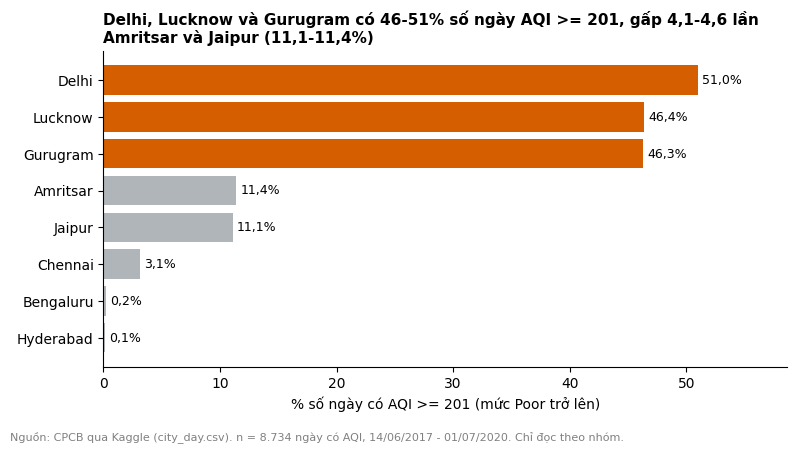

In [5]:
share_city = poor_share(win, "City").sort_values("pct_poor")     # tăng dần để cột lớn nằm trên cùng
display(share_city)

# Nhấn NHÓM 3 thành phố cao nhất bằng MỘT màu (vì Lucknow và Gurugram đổi thứ hạng khi bỏ 10% dòng, xem phần kiểm tra độ nhạy ở trên)
top3 = list(share_city.index[-3:])
hi = share_city.pct_poor.loc[top3]
lo = share_city.pct_poor.loc[["Amritsar", "Jaipur"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(share_city.index.astype(str), share_city.pct_poor.values,
               color=[ACCENT if c in top3 else NEUTRAL for c in share_city.index])
ax.bar_label(bars, labels=[vn(v, 1) + "%" for v in share_city.pct_poor.values], padding=3, fontsize=9)
ax.set_xlim(0, share_city.pct_poor.max() * 1.15)
ax.set_xlabel("% số ngày có AQI >= 201 (mức Poor trở lên)"); ax.set_ylabel("")
finish_chart(fig, ax,
             f"Delhi, Lucknow và Gurugram có {vn(hi.min())}-{vn(hi.max())}% số ngày AQI >= 201, "
             f"gấp {vn(hi.min() / lo.max(), 1)}-{vn(hi.max() / lo.min(), 1)} lần Amritsar và Jaipur "
             f"({vn(lo.min(), 1)}-{vn(lo.max(), 1)}%)", win,
             note="Chỉ đọc theo nhóm.")
save_fig(fig, "01_poor_share_city")
plt.show()


## A3. Biểu đồ 5: phân phối AQI theo thành phố

Đã lưu reports/figures/eda_05_aqi_distribution.png


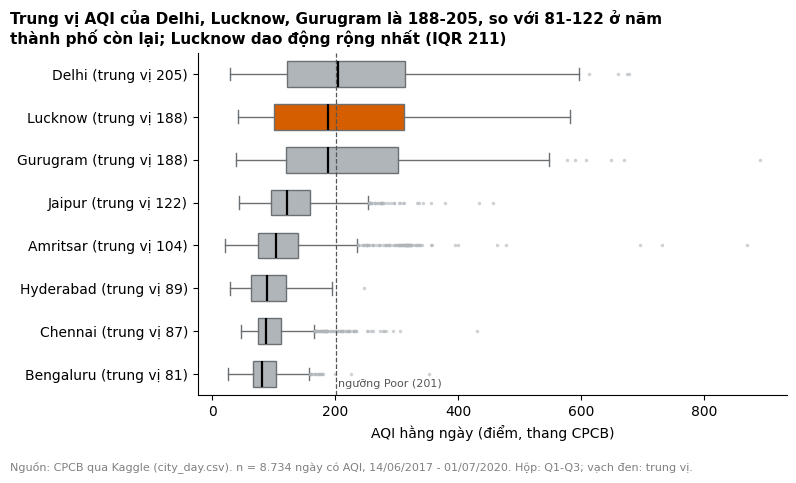

In [6]:
d = win.dropna(subset=["AQI"])
med = d.groupby("City", observed=True).AQI.median()
order = med.sort_values(ascending=False).index.tolist()           # trung vị giảm dần: cao nhất ở trên cùng
data = [d.loc[d.City == c, "AQI"].values for c in order]

# Nhấn Lucknow vì IQR lớn nhất trong 8 thành phố (xem bảng A1)
focus = stats_city["iqr"].idxmax()

fig, ax = plt.subplots(figsize=(8, 4.8))
bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6, showfliers=True,
                flierprops=dict(marker="o", markersize=2.5, markerfacecolor=NEUTRAL, markeredgecolor="none", alpha=0.6),
                medianprops=dict(color="black", linewidth=1.6),
                whiskerprops=dict(color="#6B7075"), capprops=dict(color="#6B7075"))
for patch, c in zip(bp["boxes"], order):
    patch.set_facecolor(ACCENT if c == focus else NEUTRAL)
    patch.set_edgecolor("#6B7075")
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{c} (trung vị {vn(med[c])})" for c in order])   # ghi nhãn trực tiếp
ax.invert_yaxis()                                                      # vị trí 1 ở trên cùng
ax.axvline(201, color="#555555", linestyle="--", linewidth=0.9)
ax.text(205, 0.02, "ngưỡng Poor (201)", transform=ax.get_xaxis_transform(), va="bottom", fontsize=8, color="#555555")
ax.set_xlabel("AQI hằng ngày (điểm, thang CPCB)"); ax.set_ylabel("")

top3_med = med.loc[["Delhi", "Lucknow", "Gurugram"]]
rest_med = med.drop(["Delhi", "Lucknow", "Gurugram"])
finish_chart(fig, ax,
             f"Trung vị AQI của Delhi, Lucknow, Gurugram là {vn(top3_med.min())}-{vn(top3_med.max())}, "
             f"so với {vn(rest_med.min())}-{vn(rest_med.max())} ở năm thành phố còn lại; "
             f"{focus} dao động rộng nhất (IQR {vn(stats_city.loc[focus, 'iqr'])})", win,
             note="Hộp: Q1-Q3; vạch đen: trung vị.")
# nhãn trục dài đẩy khung vẽ sang phải: dời tiêu đề về mép trái của hình để không bị cắt
fig.canvas.draw()
pos = ax.get_position()
ax.set_title(ax.get_title(loc="left"), loc="left", x=(0.01 - pos.x0) / pos.width, fontsize=11, fontweight="bold")
save_fig(fig, "05_aqi_distribution")
plt.show()


## Phát hiện của phần A (gom vào mục 5 của báo cáo)

Mỗi phát hiện phải gắn **một biểu đồ** (không có biểu đồ thì chỉ là ý kiến), kèm confounder và hạn chế.

| # | Phát hiện (có con số) | Biểu đồ | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| A1 | Trong khoảng chung 14/06/2017 – 01/07/2020, Delhi (51,0%), Lucknow (46,4%) và Gurugram (46,3%) có khoảng một nửa số ngày AQI >= 201, gấp 4,1-4,6 lần Amritsar (11,4%) và Jaipur (11,1%). Chennai chỉ 3,1%, Bengaluru 0,2% và Hyderabad 0,1% gần như không có ngày nặng. | 1 | Số và vị trí trạm đo (mỗi thành phố chỉ có một chuỗi, có thể là trạm gần đường lớn hay khu công nghiệp); quy mô đô thị và giao thông; địa lý và thời tiết (dữ liệu **không** có thời tiết và vị trí trạm). | Khoảng chung chỉ gần 3 năm, có cả giai đoạn phong tỏa COVID-19 (từ 25/3/2020). Lucknow và Gurugram, Amritsar và Jaipur, Bengaluru và Hyderabad đổi thứ hạng khi bỏ ngẫu nhiên 10% dòng, nên chỉ đọc theo **nhóm**, không xếp hạng. Amritsar thiếu 85 ngày AQI, Gurugram thiếu 44 ngày; nếu ngày thiếu rơi vào mùa nặng hoặc nhẹ thì tỉ lệ lệch theo. Chỉ có tương quan (có liên quan), không kết luận nguyên nhân. |
| A2 | Phân phối AQI của ba thành phố nhóm đầu nằm cao hơn hẳn: trung vị 188-205 so với 81-122 ở năm thành phố còn lại. Lucknow dao động rộng nhất (IQR 211, Delhi 192, Gurugram 182) so với Jaipur 63 và Amritsar 64. Trong khoảng chung, trung vị mùa của Lucknow đi từ 91 (mùa mưa) đến 325 (mùa đông) nên ngày "điển hình" phụ thuộc rất nhiều vào mùa. Cả 8 thành phố đều lệch phải (skew 0,38-2,94), nên trung vị phù hợp hơn trung bình. | 5 | Mùa vụ (biểu đồ này gộp mọi mùa nên độ rộng một phần phản ánh chênh lệch mùa chứ không chỉ độ ổn định); số và vị trí trạm; số ngày thiếu mỗi thành phố khác nhau. | Boxplot không cho biết **khi nào** nặng (phần B của nhóm). `skew` rất nhạy với vài ngày cực đoan, ví dụ Amritsar 2,94 do một số ít ngày rất cao. Có ngày AQI vượt 500 (tối đa 891 ở Gurugram) trong khi thang CPCB dừng ở 500; nhóm chưa đối chiếu nguồn gốc. Trung vị Lucknow và Gurugram (188) rất sát ngưỡng 201, nên % ngày nặng nhạy với việc chọn ngưỡng. |

**Trước khi push:** Restart & Run All không lỗi; đã tick checklist biểu đồ; đã `git pull`.

## Trả lời vấn đáp (viết bằng lời của mình)

**Confounder nào có thể giải thích khác biệt giữa các thành phố?**
Số và vị trí trạm đo (đây là điểm mạnh nhất vì mỗi thành phố chỉ có một chuỗi), quy mô đô thị và mật độ giao thông, địa lý, thời tiết và gió. Bộ dữ liệu này không có thời tiết và không có vị trí trạm, nên nhóm không thể loại trừ các yếu tố đó. Vì vậy báo cáo chỉ viết "có liên quan" và không viết "gây ra".

**Biểu đồ 1 có thể đánh lừa người đọc vội ở chỗ nào?**
(1) Ngưỡng 201 là một đường cắt cứng: ngày AQI 195 và ngày AQI 205 gần như giống nhau nhưng một ngày được tính là nặng, một ngày thì không. Trung vị Lucknow và Gurugram (188) đang nằm sát ngưỡng này. (2) Cột dài hơn không có nghĩa thành phố "ô nhiễm hơn" nếu trạm đo đặt ở chỗ khác nhau. (3) Thứ hạng giữa các thành phố có tỉ lệ gần nhau không ổn định, nên không nên nói "Lucknow cao hơn Gurugram". (4) Tỉ lệ tính trên số ngày **có** AQI, mỗi thành phố một mẫu số khác nhau. (5) Khoảng chung chỉ gần 3 năm và có phong tỏa COVID-19.

**Biểu đồ 5 có thể đánh lừa người đọc vội ở chỗ nào?**
Boxplot gộp mọi mùa, nên hộp rộng như Lucknow có thể bị hiểu là "thất thường" trong khi phần lớn là chênh lệch giữa mùa đông và mùa mưa. Các chấm ở ngoài râu chỉ là ngày xa phần giữa, chưa chắc là lỗi hay ngoại lai thật. Ngoài ra, hình dạng của hộp không nói gì về nguyên nhân.


---
# Phần B — KHI NÀO: ô nhiễm nặng rơi vào mùa nào, và có giảm qua các năm không

### Lưu ý khi đọc phần B
- Chuỗi các thành phố dài ngắn khác nhau và có vài ô **thưa dữ liệu**: ví dụ Jaipur tháng 1-6/2017 chỉ có 11 ngày có AQI, Gurugram 2016 chỉ 95 ngày. Hãy **luôn xem bảng số ngày `n_tbl`** cạnh bảng trung bình trước khi kết luận về xu hướng, và bỏ hoặc ghi chú các ô có ít ngày.
- Năm 2020 chỉ đến 01/07 và có lockdown: chỉ nêu "có liên quan", không kết luận nguyên nhân. Mùa, xu hướng giảm dần qua các năm và lockdown đều là confounder của việc "2020 thấp hơn 2019".
- Heatmap dùng `win` (khoảng chung) vì cần so các thành phố; biểu đồ xu hướng dùng `eda` nhưng **trong từng thành phố riêng**.


## B0. Bảng xu hướng tháng 1-6, kèm số ngày để biết ô nào thưa

In [7]:
h1 = eda[eda.month <= 6].dropna(subset=["AQI"])
trend_tbl = h1.pivot_table(index="City", columns="year", values="AQI", aggfunc="mean", observed=True).round(0)
n_tbl     = h1.pivot_table(index="City", columns="year", values="AQI", aggfunc="size", observed=True)
print("AQI trung bình, tháng 1-6:");  display(trend_tbl)
print("Số ngày có AQI trong ô đó (ô nhỏ = kết luận yếu):"); display(n_tbl)

AQI trung bình, tháng 1-6:


year,2015,2016,2017,2018,2019,2020
City,,,,,,
Delhi,306.0,298.0,294.0,263.0,246.0,182.0
Gurugram,NaN,239.0,319.0,250.0,211.0,159.0
Lucknow,133.0,257.0,260.0,257.0,224.0,158.0
Jaipur,NaN,NaN,83.0,165.0,132.0,105.0
Bengaluru,111.0,114.0,89.0,86.0,108.0,80.0
Amritsar,NaN,NaN,92.0,148.0,104.0,93.0
Chennai,178.0,138.0,109.0,105.0,109.0,80.0
Hyderabad,135.0,127.0,128.0,105.0,104.0,78.0


Số ngày có AQI trong ô đó (ô nhỏ = kết luận yếu):


year,2015,2016,2017,2018,2019,2020
City,,,,,,
Delhi,181.0,182.0,180.0,181.0,181.0,182.0
Gurugram,NaN,95.0,161.0,163.0,180.0,182.0
Lucknow,98.0,160.0,178.0,181.0,181.0,182.0
Jaipur,NaN,NaN,11.0,180.0,181.0,182.0
Bengaluru,102.0,180.0,181.0,177.0,181.0,182.0
Amritsar,NaN,NaN,111.0,156.0,179.0,173.0
Chennai,95.0,169.0,178.0,181.0,181.0,182.0
Hyderabad,86.0,179.0,180.0,181.0,181.0,182.0


## B1. Biểu đồ 2: heatmap thành phố x tháng

Mỗi ô thành phố x tháng có 75-107 ngày (khoảng 3 mùa của cùng một tháng).


month,1,2,3,4,5,6,7,8,9,10,11,12
City,,,,,,,,,,,,
Delhi,340.0,284.0,191.0,198.0,196.0,152.0,100.0,98.0,106.0,274.0,360.0,376.0
Lucknow,344.0,266.0,207.0,154.0,173.0,142.0,84.0,84.0,85.0,249.0,352.0,345.0
Gurugram,308.0,210.0,154.0,150.0,166.0,174.0,109.0,81.0,92.0,280.0,332.0,316.0
Jaipur,138.0,130.0,110.0,125.0,138.0,108.0,88.0,82.0,91.0,150.0,190.0,147.0
Amritsar,111.0,123.0,92.0,93.0,102.0,103.0,81.0,66.0,80.0,138.0,209.0,140.0
Hyderabad,132.0,111.0,101.0,90.0,101.0,60.0,54.0,56.0,62.0,102.0,129.0,138.0
Chennai,116.0,89.0,86.0,68.0,80.0,96.0,85.0,82.0,93.0,84.0,86.0,92.0
Bengaluru,102.0,94.0,100.0,84.0,82.0,63.0,64.0,63.0,70.0,82.0,83.0,91.0


Đã lưu reports/figures/eda_02_heatmap_city_month.png


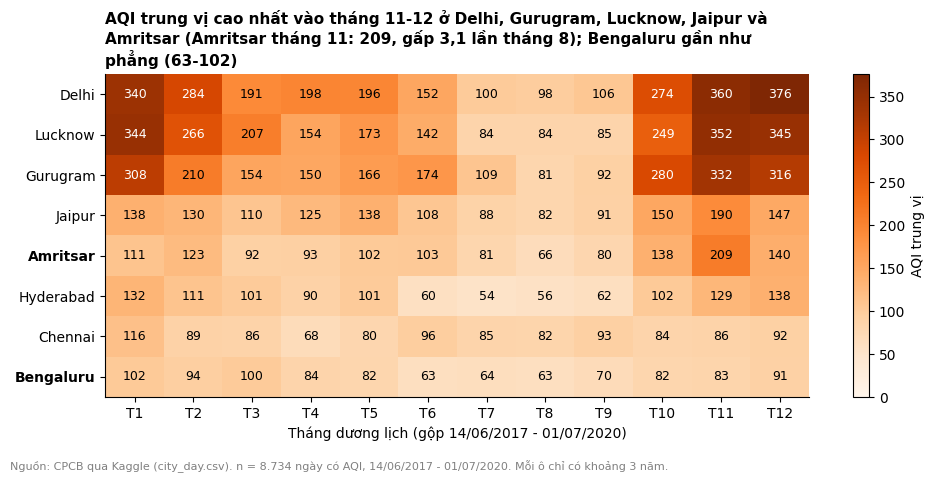

Amritsar: ngày AQI >= 201 = 117 | tháng 10-12: 89 (76%)
Bengaluru: ngày AQI >= 201 = 2 | trung vị tháng: min 63.0 max 102.0 (đỉnh/đáy 1,6 lần)


In [8]:
d = win.dropna(subset=["AQI"])
med = d.pivot_table(index="City", columns="month", values="AQI", aggfunc="median", observed=True)
n_m = d.pivot_table(index="City", columns="month", values="AQI", aggfunc="size", observed=True)
med = med.loc[d.groupby("City", observed=True).AQI.median().sort_values(ascending=False).index]   # cùng thứ tự với phần A
print(f"Mỗi ô thành phố x tháng có {n_m.min().min()}-{n_m.max().max()} ngày (khoảng 3 mùa của cùng một tháng).")
display(med.round(0))

fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(med.values, cmap="Oranges", vmin=0, aspect="auto")        # thang tuần tự, bắt đầu từ 0
ax.set_xticks(range(12)); ax.set_xticklabels([f"T{m}" for m in range(1, 13)])
ax.set_yticks(range(len(med))); ax.set_yticklabels(med.index.astype(str))
for lab in ax.get_yticklabels():
    if lab.get_text() in ("Bengaluru", "Amritsar"):
        lab.set_fontweight("bold")                                       # nhấn 2 thành phố của phần B
for i in range(med.shape[0]):
    for j in range(12):
        v = med.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 * med.values.max() else "black")
cb = fig.colorbar(im, ax=ax); cb.set_label("AQI trung vị")
ax.set_xlabel("Tháng dương lịch (gộp 14/06/2017 - 01/07/2020)"); ax.set_ylabel("")

am, bl = med.loc["Amritsar"], med.loc["Bengaluru"]
finish_chart(fig, ax,
    f"AQI trung vị cao nhất vào tháng 11-12 ở Delhi, Gurugram, Lucknow, Jaipur và Amritsar (Amritsar tháng 11: {vn(am[11])}, "
    f"gấp {vn(am[11] / am[8], 1)} lần tháng 8); Bengaluru gần như phẳng ({vn(bl.min())}-{vn(bl.max())})", win,
    note="Mỗi ô chỉ có khoảng 3 năm.")
save_fig(fig, "02_heatmap_city_month")
plt.show()

# số liệu dùng trong bảng phát hiện B1
amd = d[(d.City == "Amritsar") & (d.AQI >= 201)]
print("Amritsar: ngày AQI >= 201 =", len(amd), "| tháng 10-12:", int(amd.month.isin([10, 11, 12]).sum()),
      f"({vn(amd.month.isin([10, 11, 12]).mean() * 100)}%)")
print("Bengaluru: ngày AQI >= 201 =", int((d[d.City == "Bengaluru"].AQI >= 201).sum()), "| trung vị tháng: min", bl.min(), "max", bl.max(),
      f"(đỉnh/đáy {vn(bl.max() / bl.min(), 1)} lần)")

## B2. Biểu đồ 3: xu hướng theo năm trong từng thành phố (tháng 1-6)

Ô bị bỏ khỏi hình (quá thưa): Gurugram 2016 (95 ngày); Lucknow 2015 (98 ngày); Jaipur 2017 (11 ngày); Bengaluru 2015 (102 ngày); Amritsar 2017 (111 ngày); Chennai 2015 (95 ngày); Hyderabad 2015 (86 ngày)


Đã lưu reports/figures/eda_03_trend_city_year.png


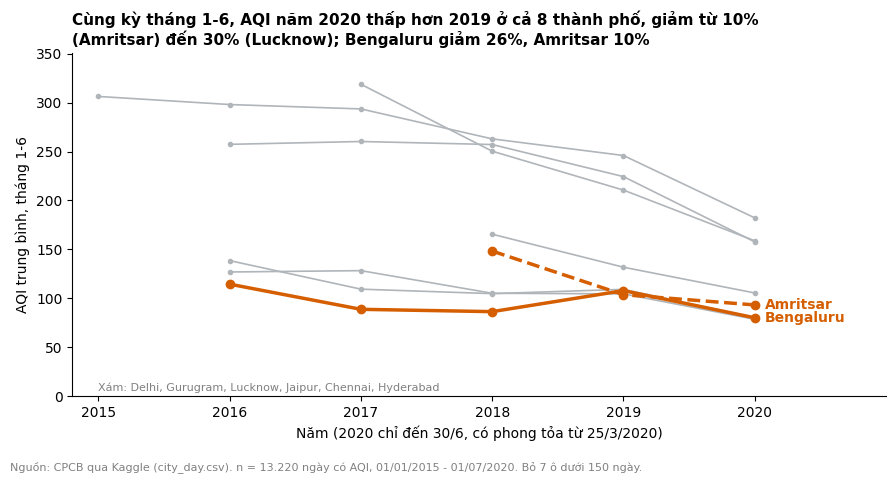

,"% đổi 2020 so với 2019, tháng 1-6"
City,
Delhi,-25.9
Gurugram,-24.6
Lucknow,-29.8
Jaipur,-20.0
Bengaluru,-25.8
Amritsar,-10.1
Chennai,-26.4
Hyderabad,-25.0


In [9]:
MIN_N = 150                                    # tháng 1-6 có khoảng 181 ngày; ô dưới 150 ngày bị bỏ khỏi hình (xem n_tbl ở B0)
trend_ok = trend_tbl_raw = h1.pivot_table(index="City", columns="year", values="AQI", aggfunc="mean", observed=True)
trend_ok = trend_tbl_raw.where(n_tbl >= MIN_N)
dropped = [f"{c} {int(y)} ({int(n_tbl.loc[c, y])} ngày)" for c in n_tbl.index for y in n_tbl.columns if n_tbl.loc[c, y] < MIN_N]
print("Ô bị bỏ khỏi hình (quá thưa):", "; ".join(dropped))

fig, ax = plt.subplots(figsize=(9, 4.8))
for c in trend_ok.index:
    s = trend_ok.loc[c].dropna()
    if c in ("Bengaluru", "Amritsar"):
        ax.plot(s.index, s.values, color=ACCENT, lw=2.5, marker="o", ls="-" if c == "Bengaluru" else "--", zorder=3)
        ax.text(s.index[-1] + 0.08, s.values[-1], c, color=ACCENT, fontsize=10, fontweight="bold", va="center")
    else:
        ax.plot(s.index, s.values, color=NEUTRAL, lw=1.2, marker="o", ms=3)
ax.text(2015.0, 5, "Xám: Delhi, Gurugram, Lucknow, Jaipur, Chennai, Hyderabad", fontsize=8, color="gray")
ax.set_xlim(2014.8, 2021.0); ax.set_ylim(0, trend_ok.max().max() * 1.1)
ax.set_xticks(range(2015, 2021)); ax.set_xlabel("Năm (2020 chỉ đến 30/6, có phong tỏa từ 25/3/2020)")
ax.set_ylabel("AQI trung bình, tháng 1-6")

chg = (trend_tbl_raw[2020] / trend_tbl_raw[2019] - 1) * 100             # 2020 so với 2019, cùng kỳ tháng 1-6
assert (chg < 0).all(), "có thành phố 2020 không thấp hơn 2019, phải sửa tiêu đề"
finish_chart(fig, ax,
    f"Cùng kỳ tháng 1-6, AQI năm 2020 thấp hơn 2019 ở cả {len(chg)} thành phố, giảm từ {vn(-chg.max())}% ({chg.idxmax()}) "
    f"đến {vn(-chg.min())}% ({chg.idxmin()}); Bengaluru giảm {vn(-chg['Bengaluru'])}%, Amritsar {vn(-chg['Amritsar'])}%", eda,
    note=f"Bỏ {len(dropped)} ô dưới {MIN_N} ngày.")
save_fig(fig, "03_trend_city_year")
plt.show()
display(chg.round(1).rename("% đổi 2020 so với 2019, tháng 1-6").to_frame())

### B3. Chẩn đoán: giảm của 2020 nằm trước hay sau phong tỏa (25/3/2020)?
Nếu chỉ do phong tỏa thì phần giảm phải xuất hiện **sau** 25/3. Tách tháng 1-6 thành hai đoạn cùng kỳ (1/1-24/3 và 25/3-30/6), so 2020 với 2019 trong **từng thành phố**. Chỉ là chẩn đoán, không kết luận nguyên nhân (mùa, thời tiết, xu hướng dài hạn vẫn là confounder).

In [10]:
def seg_mean(c, y, a, b):
    g = eda[(eda.City == c) & (eda.Date >= f"{y}-{a}") & (eda.Date <= f"{y}-{b}")].AQI.dropna()
    return g.mean(), len(g)

rows = []
for c in CITIES:
    r = {"City": c}
    for tag, (a, b) in {"truoc": ("01-01", "03-24"), "sau": ("03-25", "06-30")}.items():
        m19, n19 = seg_mean(c, 2019, a, b); m20, n20 = seg_mean(c, 2020, a, b)
        r[f"{tag}_2019"] = round(m19); r[f"{tag}_2020"] = round(m20)
        r[f"{tag}_doi_%"] = round((m20 / m19 - 1) * 100); r[f"{tag}_n_min"] = min(n19, n20)
    rows.append(r)
lock = pd.DataFrame(rows).set_index("City")
display(lock)

,truoc_2019,truoc_2020,truoc_doi_%,truoc_n_min,sau_2019,sau_2020,sau_doi_%,sau_n_min
City,,,,,,,,
Delhi,280,248,-11,83,217,126,-42,98
Gurugram,212,197,-7,83,209,126,-40,97
Lucknow,261,216,-17,83,193,107,-45,98
Jaipur,126,116,-7,83,136,96,-30,98
Bengaluru,114,96,-16,83,102,66,-36,98
Amritsar,93,108,16,81,112,80,-29,92
Chennai,120,81,-33,83,100,80,-20,98
Hyderabad,118,95,-19,83,93,64,-31,98


## Phát hiện của phần B (gom vào mục 5 của báo cáo)

| # | Phát hiện (có con số) | Biểu đồ | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| B1 | Trong khoảng chung 14/06/2017 - 01/07/2020, Delhi, Gurugram, Lucknow, Jaipur và Amritsar có AQI trung vị cao nhất vào tháng 11-12 và thấp nhất vào tháng 7-9. Amritsar: trung vị tháng 11 là 209, gấp 3,1 lần tháng 8 (66); 89/117 ngày (76%) AQI >= 201 của Amritsar rơi vào tháng 10-12. Bengaluru gần như không có mùa: trung vị tháng chỉ dao động 63-102 (đỉnh/đáy 1,6 lần) và chỉ 2 ngày AQI >= 201. | 2 | Thời tiết (gió, mưa, lớp không khí sát mặt đất mỏng vào mùa đông) và nguồn phát thải theo mùa (ví dụ đốt rơm rạ sau mùa gặt ở vùng Punjab, lễ Diwali) có thể đi cùng đỉnh tháng 10-12; đây là giả thuyết, dữ liệu **không** có thời tiết hay nguồn phát thải để kiểm. | Mỗi ô thành phố x tháng chỉ có 75-107 ngày từ khoảng 3 mùa, nên một năm bất thường làm lệch trung vị. Amritsar thiếu 85 ngày AQI (7,6%). Trung vị che đợt ô nhiễm cực đoan. Chỉ có tương quan, không kết luận nguyên nhân. |
| B2 | Cùng kỳ tháng 1-6, AQI trung bình năm 2020 thấp hơn 2019 ở cả 8 thành phố (giảm 10% ở Amritsar đến 30% ở Lucknow). Bengaluru giảm 26% (108 xuống 80), Amritsar giảm 10% (104 xuống 93). Tách theo phong tỏa: Bengaluru giảm 16% trước 25/3 (114 xuống 96) và 36% sau (102 xuống 66); Amritsar tăng 16% trước 25/3 (93 lên 108) rồi giảm 29% sau (112 xuống 80). Bengaluru không giảm đều: 114 (2016), 89 (2017), 86 (2018), 108 (2019), 80 (2020). | 3 | Phong tỏa từ 25/3/2020; mùa (hai đoạn trước và sau 25/3 khác mùa nên so với cùng đoạn của 2019); xu hướng dài hạn (Bengaluru giảm trước phong tỏa nên không chỉ do phong tỏa); thời tiết; thay đổi trạm đo và độ phủ dữ liệu. | Chỉ so 2020 với 2019, mỗi đoạn 81-98 ngày. Amritsar chỉ có từ 27/02/2017 nên chỉ so được 2018-2020 (ô 2017 có 111 ngày, đã bỏ). 7 ô dưới 150 ngày bị bỏ khỏi hình (Bengaluru 2015 có 102 ngày). Năm 2020 chỉ đến 30/6. Chỉ viết là có liên quan, không kết luận nguyên nhân. |

**Trước khi push:** Restart & Run All không lỗi; đã tick checklist biểu đồ; đã `git pull`.

---
# Phần C — CHẤT NÀO: chất nào đi cùng AQI nặng

### Lưu ý khi đọc phần C
AQI của CPCB được tính từ **mức cao nhất trong các chỉ số con của từng chất**, nên AQI và PM2.5 tương quan cao một phần **do cách tính**, không phải một phát hiện. Hãy nói rõ điều này trong báo cáo.
Khi thử dựng lại AQI từ các chất theo bảng CPCB, kết quả chỉ khớp (lệch tối đa 10 điểm) khoảng 33% số ngày, nên **không** khẳng định chắc chắn "chất nào đóng góp"; chỉ mô tả "chất nào ở mức cao nhất".


## C0. Tương quan Spearman giữa các chất đủ dữ liệu và AQI (khoảng chung)

In [11]:
corr = win[USABLE + ["AQI"]].corr(method="spearman").round(2)
corr

,PM2.5,NO2,CO,SO2,O3,AQI
PM2.5,1.00,0.50,0.44,0.34,0.25,0.91
NO2,0.50,1.00,0.43,0.27,0.26,0.52
CO,0.44,0.43,1.00,0.20,0.17,0.48
SO2,0.34,0.27,0.20,1.00,0.28,0.38
O3,0.25,0.26,0.17,0.28,1.00,0.34
AQI,0.91,0.52,0.48,0.38,0.34,1.00


### Đọc bảng C0 bằng lời

Bảng tính trên **khoảng chung** (14/06/2017 – 01/07/2020), gộp 8 thành phố. Dùng **Spearman** (tương quan hạng: hai chất cùng có ngày cao, ngày thấp thì hệ số cao; không đòi hỏi quan hệ đường thẳng nên hợp với dữ liệu lệch phải). Mỗi cặp chỉ dùng các ngày có đủ cả hai giá trị.

| Đọc | Từ bảng này |
|---|---|
| Cột `AQI` | PM2.5 **0,91**, còn NO2 0,52, CO 0,48, SO2 0,38, O3 0,34. PM2.5 đi cùng AQI chặt hơn hẳn bốn chất kia. |
| Giữa các chất với nhau | Từ 0,17 (CO với O3) đến 0,50 (PM2.5 với NO2): các chất tăng giảm khá độc lập, không chất nào "đại diện" cho các chất còn lại. |
| Vì sao PM2.5 cao như vậy | AQI của CPCB lấy **chỉ số con lớn nhất** trong các chất. Khi PM2.5 là chất cao nhất thì AQI chính là chỉ số con của PM2.5, nên tương quan cao **một phần do công thức**, không phải một phát hiện độc lập. |
| Chỉ là tương quan | Gộp 8 thành phố trộn khác biệt giữa thành phố (xem Spearman PM2.5 với AQI từng thành phố ở bảng A1 của phần A: 0,69 ở Chennai đến 0,96 ở Delhi và Lucknow). Chỉ viết "đi cùng với", không viết "gây ra". |


## C1. Khi AQI >= 201, chất nào ở mức cao nhất?

Không so **nồng độ trung bình thô** giữa các chất, vì đơn vị khác nhau (CO tính bằng mg/m³, các chất còn lại µg/m³, xem `Data_dictionary.md`): số lớn hơn chỉ vì thang đo, không phải vì chất đó "cao hơn". Trung bình lại bị vài ngày cực đoan kéo lên.

Cách làm: so **mỗi chất với chính nó**. Với từng thành phố, lấy trung vị của chất đó vào các ngày AQI >= 201 chia cho trung vị của các ngày còn lại; rồi lấy trung vị giữa các thành phố. Tỉ lệ không có đơn vị nên so được giữa các chất (1 là bằng ngày thường). Tính **trong từng thành phố** vì ngày nặng nằm chủ yếu ở 3 thành phố (Delhi, Lucknow, Gurugram: 1.575/1.850 ngày); gộp chung sẽ lẫn khác biệt giữa thành phố. Chỉ lấy thành phố có từ 100 ngày nặng trở lên, các thành phố còn lại quá ít ngày để so.


In [12]:
d = win.dropna(subset=["AQI"])

# Số ngày AQI nặng theo thành phố: chỉ so "nặng với ngày thường" ở nơi có đủ ngày nặng
heavy_n = d[d.poor].groupby("City", observed=True).size().reindex(CITIES)
print("Số ngày AQI >= 201 theo thành phố:", heavy_n.to_dict(), "| tổng:", int(heavy_n.sum()))
big = heavy_n[heavy_n >= 100].index.tolist()
print("Thành phố đủ ngày nặng để so (>= 100 ngày):", big)

# Tỉ lệ trung vị (ngày AQI >= 201) / (các ngày còn lại), tính TRONG từng thành phố rồi mới lấy trung vị giữa các thành phố
# (không gộp chung 8 thành phố vì ngày nặng nằm chủ yếu ở 3 thành phố, gộp sẽ lẫn khác biệt giữa thành phố)
ratio = pd.DataFrame({c: d[(d.City == c) & d.poor][USABLE].median() / d[(d.City == c) & ~d.poor][USABLE].median()
                      for c in big}).T.round(2)
ratio.loc["Trung vị 5 thành phố"] = ratio.median().round(2)
display(ratio)

# Trung vị nồng độ PM2.5 thật (µg/m³) để người đọc hình dung
pm = d.groupby("poor")["PM2.5"].median().round(1)
print(f"PM2.5 trung vị: ngày AQI >= 201 = {pm[True]} µg/m³; các ngày còn lại = {pm[False]} µg/m³ (gộp 8 thành phố, chỉ để hình dung)")

# AQI nặng nhưng PM2.5 chưa tới mức Poor: nghĩa là còn chất khác (kể cả PM10, ngoài USABLE) hoặc số liệu có vấn đề
low = d[d.poor & (d["PM2.5"] < 91)]
print(f"Ngày AQI >= 201 mà PM2.5 < 91 µg/m³ (chỉ số con PM2.5 theo bảng CPCB chưa tới 201): "
      f"{len(low)}/{int(d.poor.sum())} ngày ({vn(len(low) / d.poor.sum() * 100, 1)}%)")
print(low.groupby("City", observed=True).size().reindex(CITIES).dropna().astype(int).to_dict())

# Ngày nặng rơi vào mùa nào (để biết mùa là confounder chung của mọi chất)
ss = d[d.poor].season.value_counts().reindex(SEASON_ORDER)
print("Ngày AQI >= 201 theo mùa:", ss.to_dict(), f"| tháng 10-2: {vn((ss['Đông (12-2)'] + ss['Sau mưa (10-11)']) / ss.sum() * 100, 1)}%")

Số ngày AQI >= 201 theo thành phố: {'Delhi': 564, 'Gurugram': 495, 'Lucknow': 516, 'Jaipur': 121, 'Bengaluru': 2, 'Amritsar': 117, 'Chennai': 34, 'Hyderabad': 1} | tổng: 1850
Thành phố đủ ngày nặng để so (>= 100 ngày): ['Delhi', 'Gurugram', 'Lucknow', 'Jaipur', 'Amritsar']


,PM2.5,NO2,CO,SO2,O3
Delhi,2.99,1.74,1.62,1.41,1.21
Gurugram,2.47,1.37,1.63,1.07,0.94
Lucknow,3.13,2.07,1.17,1.58,1.15
Jaipur,2.06,1.43,1.23,0.97,1.06
Amritsar,2.82,1.66,1.80,1.09,0.92
Trung vị 5 thành phố,2.82,1.66,1.62,1.09,1.06


PM2.5 trung vị: ngày AQI >= 201 = 137.1 µg/m³; các ngày còn lại = 42.0 µg/m³ (gộp 8 thành phố, chỉ để hình dung)
Ngày AQI >= 201 mà PM2.5 < 91 µg/m³ (chỉ số con PM2.5 theo bảng CPCB chưa tới 201): 225/1850 ngày (12,2%)
{'Delhi': 82, 'Gurugram': 40, 'Lucknow': 30, 'Jaipur': 44, 'Bengaluru': 1, 'Amritsar': 21, 'Chennai': 6, 'Hyderabad': 1}
Ngày AQI >= 201 theo mùa: {'Đông (12-2)': 754, 'Hè (3-5)': 332, 'Mưa (6-9)': 163, 'Sau mưa (10-11)': 601} | tháng 10-2: 73,2%


### Đọc kết quả C1

- **PM2.5 cao nhất ở cả 5 thành phố.** Trung vị PM2.5 vào ngày nặng gấp **2,1 lần (Jaipur) đến 3,1 lần (Lucknow)** ngày thường, trung vị 5 thành phố là 2,8 lần. Gộp 8 thành phố cho hình dung cụ thể: 137,1 so với 42,0 µg/m³.
- NO2 gấp 1,4-2,1 lần (trung vị 1,7), CO gấp 1,2-1,8 lần (trung vị 1,6). SO2 (1,0-1,6) và O3 (0,9-1,2) gần như không đổi so với ngày thường, có thành phố còn thấp hơn một chút.
- **Mùa là yếu tố chung:** 73,2% ngày nặng rơi vào tháng 10-2. Mọi chất đều cao hơn vào những tháng này, nên NO2 và CO "cao hơn ngày thường" có thể một phần là do mùa chứ không do nguồn riêng của từng chất (giả thuyết, dữ liệu không có thời tiết để kiểm).
- **Giới hạn quan trọng:** 225/1.850 ngày nặng (12,2%) có PM2.5 dưới 91 µg/m³, mức mà chỉ số con PM2.5 theo bảng CPCB chưa tới 201. Ở những ngày đó AQI nặng là do chất khác (có thể là PM10, **không nằm trong 5 chất** vì thiếu dữ liệu ở 3 thành phố) hoặc số liệu có vấn đề. Jaipur có 44/121 ngày nặng (36%) rơi vào trường hợp này.


## C2. Biểu đồ 4: PM2.5 đi cùng AQI chặt nhất và tăng nhiều nhất khi AQI nặng

Đã lưu reports/figures/eda_04_pm25_aqi.png


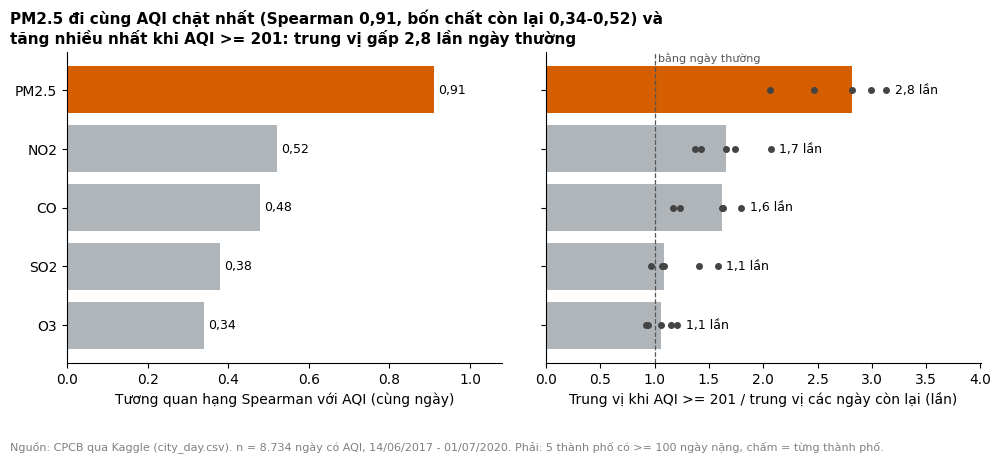

In [13]:
rho = corr["AQI"].drop("AQI").sort_values()                      # tăng dần để cột lớn nằm trên cùng
rt = ratio.loc[big, rho.index]                                   # 5 thành phố, cùng thứ tự chất
rt_med = ratio.loc["Trung vị 5 thành phố", rho.index]
assert rho.idxmax() == "PM2.5" and rt_med.idxmax() == "PM2.5", "PM2.5 không còn đứng đầu, phải sửa tiêu đề"

others = rho.drop("PM2.5")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
colors = [ACCENT if s == "PM2.5" else NEUTRAL for s in rho.index]

# Trái: tương quan hạng với AQI (khoảng chung, 8 thành phố)
b1 = ax1.barh(rho.index, rho.values, color=colors)
ax1.bar_label(b1, labels=[vn(v, 2) for v in rho.values], padding=3, fontsize=9)
ax1.set_xlim(0, 1.08)
ax1.set_xlabel("Tương quan hạng Spearman với AQI (cùng ngày)")
ax1.set_ylabel("")

# Phải: tỉ lệ trung vị ngày nặng / ngày thường, tính trong từng thành phố (chấm xám = từng thành phố)
b2 = ax2.barh(rt_med.index, rt_med.values, color=colors)
for i, s in enumerate(rt_med.index):
    ax2.scatter(rt[s].values, [i] * len(rt), s=16, color="#444444", zorder=3)
    ax2.text(rt[s].max() + 0.08, i, f"{vn(rt_med[s], 1)} lần", va="center", fontsize=9)
ax2.axvline(1, color="#555555", linestyle="--", linewidth=0.9)
ax2.text(1.03, 1.0, "bằng ngày thường", transform=ax2.get_xaxis_transform(), va="top", fontsize=8, color="#555555")
ax2.set_xlim(0, rt.max().max() * 1.28)
ax2.set_xlabel("Trung vị khi AQI >= 201 / trung vị các ngày còn lại (lần)")

finish_chart(fig, ax1,
             f"PM2.5 đi cùng AQI chặt nhất (Spearman {vn(rho['PM2.5'], 2)}, bốn chất còn lại {vn(others.min(), 2)}-{vn(others.max(), 2)}) "
             f"và tăng nhiều nhất khi AQI >= 201: trung vị gấp {vn(rt_med['PM2.5'], 1)} lần ngày thường",
             win, note=f"Phải: {len(big)} thành phố có >= 100 ngày nặng, chấm = từng thành phố.")
fig.subplots_adjust(bottom=0.2, wspace=0.1)       # chừa chỗ cho nhãn trục và chú thích nguồn
# nhãn trục dài đẩy khung vẽ sang phải: dời tiêu đề về mép trái của hình (cùng cách phần A)
fig.canvas.draw()
pos = ax1.get_position()
ax1.set_title(ax1.get_title(loc="left"), loc="left", x=(0.01 - pos.x0) / pos.width, fontsize=11, fontweight="bold")
save_fig(fig, "04_pm25_aqi")
plt.show()

## Phát hiện của phần C

| # | Phát hiện (có con số) | Biểu đồ | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| C1 | Trong khoảng chung 14/06/2017 - 01/07/2020, PM2.5 là chất đi cùng AQI chặt nhất (Spearman 0,91; NO2 0,52, CO 0,48, SO2 0,38, O3 0,34). Vào ngày AQI >= 201, trung vị PM2.5 cao gấp 2,1-3,1 lần ngày thường ở cả 5 thành phố có từ 100 ngày nặng (trung vị 2,8 lần; 137 so với 42 µg/m³ khi gộp). NO2 gấp 1,7 lần, CO 1,6 lần, SO2 và O3 chỉ khoảng 1,1 lần. | 4 | **Cách tính AQI:** AQI lấy chỉ số con lớn nhất nên PM2.5 cao khi AQI cao một phần là do công thức; ngày nặng lại được chọn theo chính AQI. **Mùa:** 73,2% ngày nặng rơi vào tháng 10-2, mọi chất đều cao hơn vào mùa này nên NO2, CO cao hơn có thể do thời tiết chung. **PM10** bị loại khỏi so sánh. | 225/1.850 ngày nặng (12,2%) có PM2.5 < 91 µg/m³ (chỉ số con chưa tới 201): ở đó chất quyết định là chất khác hoặc số liệu có vấn đề (Jaipur 44/121 ngày). Chỉ mô tả "chất nào cao hơn bình thường", **không** nói chất nào "đóng góp" bao nhiêu (nhóm thử dựng lại AQI từ các chất theo bảng CPCB chỉ khớp khoảng 33% số ngày). Chỉ có tương quan. |
| C2 | Phần "chất nào" chỉ áp dụng cho 5 thành phố có ngày nặng: Delhi 564, Lucknow 516, Gurugram 495, Jaipur 121, Amritsar 117 ngày. Chennai chỉ có 34 ngày, Bengaluru 2 và Hyderabad 1 ngày AQI >= 201, quá ít để nói về chất nào. | 4 (nửa phải) | Thành phố nhiều ngày nặng cũng là thành phố có mùa đông lạnh và khô ở phía bắc, nên "chất nào" ở nhóm này có thể không đúng cho phía nam (giả thuyết, dữ liệu không có thời tiết). | Với 3 thành phố phía nam, kết luận về chất chỉ có thể là "hầu như không có ngày nặng" (xem biểu đồ 1), không phải "chất X cao nhất". |


---
## Tổng hợp cuối

### Mục 5: 5 phát hiện chính
Lấy từ ba bảng "phát hiện của phần ..." (phần A, B, C). Mỗi ý gắn đúng một biểu đồ; tất cả so sánh giữa thành phố dùng khoảng chung 14/06/2017 - 01/07/2020, trừ phát hiện 4.

| # | Phát hiện chính | Biểu đồ | Từ phần |
|---|---|---|---|
| 1 | **Ở đâu:** Delhi (51,0%), Lucknow (46,4%) và Gurugram (46,3%) có khoảng một nửa số ngày AQI >= 201, gấp 4,1-4,6 lần Amritsar (11,4%) và Jaipur (11,1%). Chennai (3,1%), Bengaluru (0,2%) và Hyderabad (0,1%) gần như không có ngày nặng. Chỉ đọc theo ba nhóm, không xếp hạng từng thành phố. | 1 | phần A (A1) |
| 2 | **Khi nào:** AQI trung vị cao nhất vào tháng 11-12 và thấp nhất vào tháng 7-9 ở Delhi, Gurugram, Lucknow, Jaipur và Amritsar (Delhi: 376 vào tháng 12 so với 98 vào tháng 8). Ở Amritsar, 89/117 ngày nặng (76%) rơi vào tháng 10-12. Bengaluru gần như không có mùa (trung vị tháng 63-102). | 2 | phần B (B1) |
| 3 | **Chất nào:** PM2.5 đi cùng AQI chặt nhất (Spearman 0,91; các chất khác 0,34-0,52) và tăng nhiều nhất vào ngày AQI >= 201: trung vị gấp 2,8 lần ngày thường, NO2 1,7 lần, CO 1,6 lần, SO2 và O3 khoảng 1,1 lần. Một phần là do công thức tính AQI. | 4 | phần C (C1) |
| 4 | **Xu hướng:** cùng kỳ tháng 1-6, AQI năm 2020 thấp hơn 2019 ở cả 8 thành phố (giảm 10% ở Amritsar đến 30% ở Lucknow), nhưng 7/8 thành phố đã thấp hơn 2019 trước phong tỏa 25/3 (giảm 7% đến 33%; riêng Amritsar tăng 16%), nên không thể gán toàn bộ cho phong tỏa. | 3 | phần B (B2) |
| 5 | **Mức dao động:** trung vị AQI của ba thành phố đầu là 188-205, so với 81-122 ở năm thành phố còn lại. Lucknow dao động rộng nhất (IQR 211), phần lớn là chênh lệch mùa: trung vị mùa đông 325, mùa mưa 91. | 5 | phần A (A2) |

### Mục 6: hạn chế (cụ thể, mỗi ý gắn với kết luận mà nó đe dọa)

Số liệu trong bảng đã tự kiểm lại bằng `win` và bảng độ nhạy ở mục kiểm tra độ nhạy.

| # | Hạn chế (cụ thể) | Kết luận bị đe dọa | Có thể làm đổi bao nhiêu |
|---|---|---|---|
| 1 | Khoảng chung chỉ gần 3 năm (14/06/2017 - 01/07/2020), mỗi ô thành phố x tháng chỉ có 75-107 ngày từ khoảng 3 mùa. | Mùa cao điểm (biểu đồ 2) và % ngày nặng (biểu đồ 1). | Một năm bất thường làm lệch trung vị tháng. Thử bỏ ngẫu nhiên 10% ngày (200 lần): % ngày nặng đổi khoảng 2 điểm phần trăm (Delhi 49,3-53,1%), nhóm đầu (44,6-53,1%) vẫn tách khỏi nhóm giữa (10,0-12,2%). |
| 2 | Hai thành phố có tỉ lệ gần nhau đổi chỗ khi bỏ 10% dòng: Lucknow và Gurugram giữ đúng thứ hạng chỉ 59% số lần, Amritsar và Jaipur 76%. | Câu "thành phố X nặng hơn Y". | Không xếp hạng trong cùng nhóm; chỉ kết luận giữa các nhóm. |
| 3 | Mỗi thành phố chỉ có một chuỗi; dữ liệu không có vị trí và số trạm đo, không có thời tiết. | Mọi kết luận "ở đâu" và "vì sao" (biểu đồ 1, 2, 5). | Không định lượng được. Vì vậy báo cáo chỉ viết "có liên quan", không viết "gây ra". |
| 4 | PM10 không dùng được (thiếu 100% ở Lucknow, 84,5% ở Chennai, 52,4% ở Gurugram); NH3 thiếu 92,9% ở Gurugram. So sánh chất chỉ gồm 5 chất (PM2.5, NO2, CO, SO2, O3). | "PM2.5 là chất cao nhất khi AQI nặng" (biểu đồ 4). | 225/1.850 ngày nặng (12,2%) có PM2.5 < 91 µg/m³ nên chưa đủ làm AQI >= 201; ở Jaipur là 44/121 ngày (36%). Ở những ngày đó chất quyết định nằm ngoài 5 chất hoặc số liệu có vấn đề. |
| 5 | AQI tính từ chỉ số con lớn nhất của các chất, nên AQI và PM2.5 liên hệ một phần do công thức; nhóm thử dựng lại AQI chỉ khớp khoảng 33% số ngày. | "PM2.5 chiếm bao nhiêu phần AQI" (biểu đồ 4). | Không trả lời được; báo cáo chỉ nói chất nào cao hơn bình thường, không nói đóng góp. |
| 6 | 24 ngày (41 ô) nghi lỗi cảm biến đã đặt NaN nhưng chưa đối chiếu nguồn CPCB; còn điểm chưa xử lý (Gurugram 30/08/2017: PM2.5 643,7, AQI 891, hai ngày cạnh PM2.5 chỉ 6,4 và 33,3). | Đỉnh của PM2.5 và AQI, độ lệch `skew`, `std` (biểu đồ 5). | % ngày nặng gần như không đổi (1 ngày trong 1.070 ngày có AQI của Gurugram, khoảng 0,1 điểm phần trăm), nhưng `skew` và `std` của Gurugram bị kéo lên. |
| 7 | Dữ liệu dừng ở 01/07/2020: không có mùa cao điểm 10-12/2020; năm 2020 có phong tỏa từ 25/3; mỗi đoạn so 2020 với 2019 chỉ 81-98 ngày; Amritsar chỉ có từ 27/02/2017. | "AQI 2020 thấp hơn 2019" (biểu đồ 3). | Phong tỏa không giải thích hết: 7/8 thành phố đã giảm 7-33% trước 25/3, còn Amritsar tăng 16% trước phong tỏa rồi giảm 29% sau. |

### Bộ câu vấn đáp
Câu trả lời ngắn cho 5 câu W8 (liệt kê ở mục câu hỏi vấn đáp phía trên) và các câu riêng của đề tài. Cả nhóm tập trả lời cho **bất kỳ thành phố nào**; số liệu lấy từ `reports/cleaning_log_8cities.md` và các bảng trong notebook này.

**1. Vì sao xử lý missing theo cách đó?**
Nội suy tuyến tính theo thời gian chỉ cho khoảng thiếu từ 14 ngày trở xuống và nằm giữa hai giá trị thật, vì khoảng ngắn thì đường thẳng hợp lý. Khoảng dài giữ NaN vì nội suy qua khối dài là bịa số (hàm cũ điền nhầm 1.316 ô ở khoảng dài, đã sửa). AQI không điền vì là biến kết quả; điền là tạo kết quả giả.

**2. Cơ chế thiếu của cột này là gì, bằng chứng nào?**
Thiếu theo khối thời gian dài (cảm biến chưa lắp hoặc ngừng): ở 9 cặp (thành phố, cột) thiếu từ 20% trở lên, 100% ngày thiếu nằm trong khoảng dài hơn 14 ngày. Nên không phải thiếu ngẫu nhiên hoàn toàn (MCAR) mà gần với MAR theo thời gian: AQI trung bình ở ngày thiếu và ngày có lệch từ 0% đến +82% tùy cột. Không loại trừ được MNAR (thiếu vì giá trị quá cao hoặc thấp) vì không có nguồn ngoài để đối chiếu.

**3. Nếu xoá ngẫu nhiên 10% dòng, kết luận có đổi không?**
Không đổi kết luận theo nhóm. % ngày nặng chỉ đổi khoảng 2 điểm phần trăm (Delhi 49,3-53,1%) và nhóm đầu vẫn tách khỏi nhóm giữa. Thứ hạng cặp Lucknow-Gurugram giữ chỉ 59% số lần, nên báo cáo chia ba nhóm thay vì xếp hạng từng thành phố.

**4. Biểu đồ này có thể đánh lừa người đọc vội ở chỗ nào? (biểu đồ 4)**
(1) Cột 0,91 trông như một phát hiện, nhưng một phần do công thức tính AQI. (2) Ngày nặng được chọn theo AQI, nên PM2.5 cao hơn ở những ngày đó gần như là điều tất yếu. (3) "2,8 lần" là trung vị của 5 thành phố, từng thành phố từ 2,1 đến 3,1 (các chấm). (4) SO2 và O3 gần bằng ngày thường không có nghĩa là không quan trọng: 12,2% ngày nặng có PM2.5 chưa tới mức nặng, chất quyết định có thể là PM10, vốn không nằm trong biểu đồ. (5) Biểu đồ không nói chất nào gây ra ô nhiễm.

**5. Confounder hợp lý cho quan hệ vừa mô tả là gì?**
Cho biểu đồ 4: **mùa và thời tiết**. 73,2% ngày nặng rơi vào tháng 10-2, mọi chất cùng cao hơn vào mùa này, nên NO2 và CO cao hơn ngày thường có thể là do thời tiết chung (gió yếu, không khí sát mặt đất ít xáo trộn; giả thuyết, dữ liệu không có thời tiết). Thêm nữa: vị trí trạm đo (mỗi thành phố một chuỗi) và PM10 bị loại khỏi so sánh. Cho biểu đồ 1: số và vị trí trạm, quy mô đô thị, địa lý. Cho biểu đồ 3: mùa, xu hướng dài hạn, phong tỏa.

**Câu riêng của đề tài**
- *Vì sao dùng khoảng chung?* Chuỗi mỗi thành phố bắt đầu một thời điểm (Gurugram 27/11/2015, Amritsar 27/02/2017, Jaipur 14/06/2017). Nếu so cả chuỗi, thành phố có chuỗi dài có thêm các mùa đông mà thành phố khác không có, nên chênh lệch phản ánh độ dài chuỗi. Khoảng chung 14/06/2017 - 01/07/2020 cho mọi thành phố cùng 3 mùa đông.
- *Vì sao ngưỡng 201?* Là đầu mức Poor trong thang CPCB (201-300; trên 300 là Very Poor), mức cần cảnh báo sức khỏe. Hạn chế: đường cắt cứng, trung vị Lucknow và Gurugram (188) nằm sát ngưỡng nên % ngày nặng nhạy với việc chọn ngưỡng.
- *Vì sao tháng 1-6 khi so các năm?* Dữ liệu năm 2020 dừng ở 01/07, nên chỉ tháng 1-6 có đủ ở cả 6 năm; so cùng kỳ để không lẫn chênh lệch mùa.
- *Vì sao PM10 và NH3 không dùng làm biến?* Theo quy ước nhóm, cột thiếu từ 60% trở lên thì không dùng: PM10 thiếu 100% ở Lucknow, 84,5% ở Chennai; NH3 thiếu 92,9% ở Gurugram. Vì vậy `USABLE` chỉ gồm 5 chất đủ dữ liệu ở cả 8 thành phố.

**Trước khi push:** Restart & Run All không lỗi; đã tick checklist biểu đồ; đã `git pull`.
